**Objetivo:** Calcular a conectividade funcional por meio da correlação de Pearson entre as 200 ROIs do atlas CC200 para cada participante.

**Entrada:** `Data/roi_timeseries/roi_timeseries_abide.pkl`, produzido no Caderno 02.

**Processamento:** aplicação de `ConnectivityMeasure(kind="correlation")` às séries temporais de cada participante, resultando em uma matriz de conectividade funcional de dimensão 200 × 200.

**Saída principal:** `Data/conectivity/connectivity_matrices_abide.pkl`.

**Visualização:** uma matriz de conectividade é apresentada ao final do notebook exclusivamente como exemplo didático.

A transformação das matrizes 200 × 200 em vetores contendo as 19.900 conexões do triângulo superior sem a diagonal será realizada posteriormente no Caderno 07, durante a preparação dos dados para os modelos de classificação.uma 

In [1]:

import sys
from pathlib import Path

_raiz = Path.cwd().resolve()
for _cand in (_raiz, *_raiz.parents):
    if (_cand / 'src' / 'config.py').exists():
        _raiz = _cand
        break
else:
    raise RuntimeError(
        'Não foi possível localizar a pasta src/config.py a partir de '
        f'{Path.cwd()}. Abra a pasta TCC_TEA_TDAH/ no VS Code.'
    )
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import os
import random
import numpy as np

from src.config import BASE_DIR, PATHS, SEED, criar_pastas
from src.utils import exigir_arquivo

criar_pastas()

random.seed(SEED)
np.random.seed(SEED)

print('Projeto (BASE_DIR) =', BASE_DIR)

Projeto (BASE_DIR) = /home/maria/TCC_TEA


In [2]:
# ============================================================
# CARREGAMENTO DAS SÉRIES TEMPORAIS
# ============================================================

exigir_arquivo(
    PATHS['roi_timeseries']
    / 'roi_timeseries_abide.pkl',
    '02_Download_ABIDE.ipynb'
)

import pickle
import numpy as np

from nilearn.connectome import ConnectivityMeasure

timeseries_path = (
    PATHS['roi_timeseries']
    / 'roi_timeseries_abide.pkl'
)

with open(
    timeseries_path,
    'rb'
) as f:

    roi_timeseries = pickle.load(f)

# ------------------------------------------------------------
# Garantir SUB_ID como string
# ------------------------------------------------------------

roi_timeseries = {
    str(sub_id): np.asarray(ts)
    for sub_id, ts in roi_timeseries.items()
}

# ------------------------------------------------------------
# Organizar IDs e séries
# ------------------------------------------------------------

sub_ids = list(
    roi_timeseries.keys()
)

series_list = [
    roi_timeseries[sub_id]
    for sub_id in sub_ids
]

# ------------------------------------------------------------
# Conferência
# ------------------------------------------------------------

print(
    f'{len(series_list)} sujeitos carregados '
    'para cálculo de conectividade.'
)

print(
    'Primeiro participante:',
    sub_ids[0]
)

print(
    'Shape da primeira série:',
    series_list[0].shape
)

print(
    'Número de ROIs:',
    series_list[0].shape[1]
)

871 sujeitos carregados para cálculo de conectividade.
Primeiro participante: 50003
Shape da primeira série: (196, 200)
Número de ROIs: 200


### Correlação de Pearson entre todas as ROIs, para cada sujeito

In [3]:
conn_measure = ConnectivityMeasure(kind='correlation')
connectivity_matrices = conn_measure.fit_transform(series_list)

print('Shape das matrizes de conectividade:', connectivity_matrices.shape)

Shape das matrizes de conectividade: (871, 200, 200)


### Salva as matrizes completas (200x200)

In [4]:
# ============================================================
# SALVAR MATRIZES DE CONECTIVIDADE
# ============================================================

conn_dict = {
    str(sub_id): np.asarray(mat)
    for sub_id, mat in zip(
        sub_ids,
        connectivity_matrices
    )
}

# ------------------------------------------------------------
# Conferências
# ------------------------------------------------------------

print(
    'Número de matrizes:',
    len(conn_dict)
)

print(
    'Shape de uma matriz:',
    next(iter(conn_dict.values())).shape
)

# Verificar valores inválidos
problemas = [
    sub_id
    for sub_id, mat in conn_dict.items()
    if not np.isfinite(mat).all()
]

print(
    'Matrizes com NaN/Inf:',
    len(problemas)
)

if problemas:

    print(
        'Exemplos:',
        problemas[:10]
    )

# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

out_path = (
    PATHS['conectivity']
    / 'connectivity_matrices_abide.pkl'
)

with open(
    out_path,
    'wb'
) as f:

    pickle.dump(
        conn_dict,
        f
    )

print()
print(
    'Matrizes salvas em:',
    out_path
)

Número de matrizes: 871
Shape de uma matriz: (200, 200)
Matrizes com NaN/Inf: 0

Matrizes salvas em: /home/maria/TCC_TEA/Data/conectivity/connectivity_matrices_abide.pkl


### Exemplo didático — matriz de conectividade de um participante

A visualização abaixo possui finalidade exclusivamente didática,
para ilustrar a representação da conectividade funcional entre as
200 ROIs.

A figura não constitui uma etapa adicional do pipeline experimental.

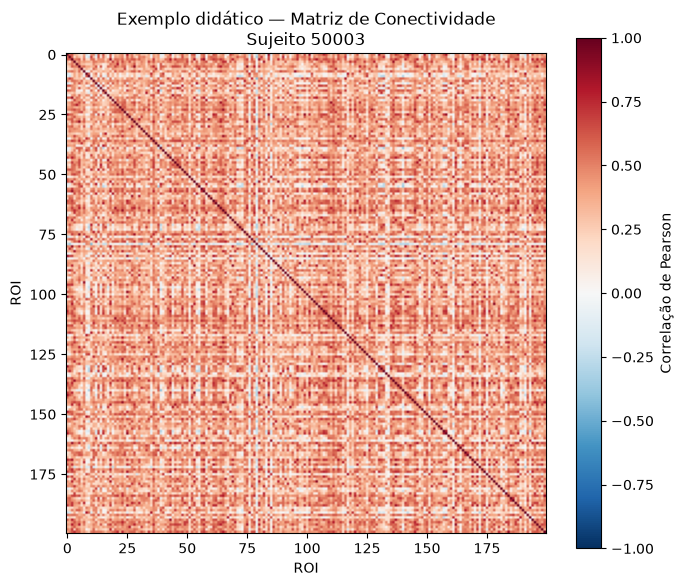

In [5]:
# ============================================================
# FIGURA DIDÁTICA — MATRIZ DE CONECTIVIDADE
# ============================================================
#
# Esta figura é exclusivamente ilustrativa.
# Ela não representa uma etapa adicional do pipeline.
# ============================================================

import matplotlib.pyplot as plt

plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    connectivity_matrices[0],
    vmin=-1,
    vmax=1,
    cmap='RdBu_r'
)

plt.colorbar(
    label='Correlação de Pearson'
)

plt.xlabel(
    'ROI'
)

plt.ylabel(
    'ROI'
)

plt.title(
    f'Exemplo didático — Matriz de Conectividade\n'
    f'Sujeito {sub_ids[0]}'
)

plt.tight_layout()

plt.savefig(
    PATHS['figures']
    / '04_exemplo_matriz_conectividade.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()